# 01 — Preprocessing

Foundation notebook for the BART wearable-EEG artifact classification pipeline.
It turns the raw `.xdf` recordings stored in `../data/xdf/` into three artifacts
consumed by every downstream notebook in `../notebooks/`:

| File                       | Purpose                                                                 |
|----------------------------|-------------------------------------------------------------------------|
| `features.pkl`             | Hand-crafted feature matrix `X` + hierarchical labels for the RF stack. |
| `windows_raw.pkl`          | Raw 4-channel windows (`n × 4 × 500`) for the CNN / EEGNet notebooks.   |
| `window_summary.csv`       | Human-readable per-window metadata for inspection.                      |

The pipeline does, per recording:
1. **Load** EEG and marker streams from XDF.
2. **Preprocess** the signal (drop dead channels, band-pass, notch, average reference).
3. **Build a per-sample label timeline** from the experimental markers.
4. **Extract sliding windows** that do not cross task boundaries.
5. **Compute hand-crafted features** on each window.

## Section 1 — Imports & Configuration

A single `CONFIG` dictionary holds every parameter used by the pipeline.
Nothing — paths, sampling rate, channel layout, label mappings — is hardcoded
outside of it. Derived constants (`N_ACTIVE_CHANNELS`, `WINDOW_SAMPLES`,
`STEP_SAMPLES`) are computed from the primary entries so that changing
e.g. `WINDOW_SEC` propagates everywhere.

The device exposes 8 physical channels (`Fp1, Fp2, F7, F8, T3, T4, T5, T6`)
but only the first four carry real EEG signal. The temporal channels carry
the reference electrode signal repeated identically across all four of them —
confirmed by zero RF feature importance across every experiment. They are
loaded for construction (MNE requires names for each row) and then
**dropped before filtering and average referencing** so they do not corrupt
the common-average reference.

In [1]:
import pickle
import warnings
from pathlib import Path
from typing import Optional

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pyxdf
from scipy.signal import welch
from scipy.stats import kurtosis, skew

mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)

CONFIG: dict = {
    # I/O
    "DATA_DIR":   Path("../data/xdf"),
    "OUTPUT_DIR": Path("processed_xdf"),

    # Acquisition
    "CH_NAMES":        ["Fp1", "Fp2", "F7", "F8", "T3", "T4", "T5", "T6"],
    "ACTIVE_CH_NAMES": ["Fp1", "Fp2", "F7", "F8"],
    "SFREQ":           250,    # Hz

    # Windowing
    "WINDOW_SEC": 2.0,
    "STEP_SEC":   0.5,

    # Filtering
    "BANDPASS":   (0.5, 99.0),
    "NOTCH_FREQ": [50.0, 100.0],

    # Marker -> fine-label mapping for KEPT regions.
    # Both the region-opening '*_start' marker and the per-trial repeat cue
    # map to the same fine label.
    "REGION_LABEL_MAP": {
        # ocular artifacts
        "blink_start":      "blink",
        "blink":            "blink",
        "look_left_start":  "look_left",
        "look left":        "look_left",
        "look_right_start": "look_right",
        "look right":       "look_right",
        # head / muscle artifacts
        "clench_start":     "clench",
        "clench":           "clench",
        "horiz_head_start": "horiz_head",
        "horiz head":       "horiz_head",
        "vert_head_start":  "vert_head",
        "vert head":        "vert_head",
        # rest blocks (pooled)
        "eyes_open_1_start":   "rest",
        "eyes_open_2_start":   "rest",
        "eyes_closed_1_start": "rest",
        "eyes_closed_2_start": "rest",
    },

    # Markers that open a region we discard entirely.
    "DISCARD_MARKERS": {
        "intertask_start",
        "math_start",
        "math",
        "protocol_start",
        "protocol_end",
    },

    # Hierarchical label sets
    "ARTIFACT_LABELS":    {"blink", "look_left", "look_right",
                           "clench", "horiz_head", "vert_head"},
    "OCULAR_LABELS":      {"blink", "look_left", "look_right"},
    "HEAD_MUSCLE_LABELS": {"clench", "horiz_head", "vert_head"},

    # Subjects excluded from the pipeline (none by default).
    "EXCLUDE_SUBJECTS": set(),
}

# Derived constants
CONFIG["N_CHANNELS"]        = len(CONFIG["CH_NAMES"])
CONFIG["N_ACTIVE_CHANNELS"] = len(CONFIG["ACTIVE_CH_NAMES"])
CONFIG["WINDOW_SAMPLES"]    = int(CONFIG["WINDOW_SEC"] * CONFIG["SFREQ"])
CONFIG["STEP_SAMPLES"]      = int(CONFIG["STEP_SEC"]   * CONFIG["SFREQ"])

CONFIG["OUTPUT_DIR"].mkdir(parents=True, exist_ok=True)

print("Configuration loaded.")
print(f"  Data dir            : {CONFIG['DATA_DIR'].resolve()}")
print(f"  Output dir          : {CONFIG['OUTPUT_DIR'].resolve()}")
print(f"  Physical channels   : {CONFIG['CH_NAMES']}")
print(f"  Active channels ({CONFIG['N_ACTIVE_CHANNELS']}) : {CONFIG['ACTIVE_CH_NAMES']}")
print(f"  Window              : {CONFIG['WINDOW_SEC']} s "
      f"({CONFIG['WINDOW_SAMPLES']} samples)  "
      f"step {CONFIG['STEP_SEC']} s "
      f"({CONFIG['STEP_SAMPLES']} samples)")
print(f"  Bandpass / notch    : {CONFIG['BANDPASS']} Hz / {CONFIG['NOTCH_FREQ']} Hz")
print(f"  Excluded subjects   : {sorted(CONFIG['EXCLUDE_SUBJECTS']) or 'none'}")

Configuration loaded.
  Data dir            : C:\Users\Mirko\Downloads\AY_2526_project_group_03\data\xdf
  Output dir          : C:\Users\Mirko\Downloads\AY_2526_project_group_03\notebooks\processed_xdf
  Physical channels   : ['Fp1', 'Fp2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6']
  Active channels (4) : ['Fp1', 'Fp2', 'F7', 'F8']
  Window              : 2.0 s (500 samples)  step 0.5 s (125 samples)
  Bandpass / notch    : (0.5, 99.0) Hz / [50.0, 100.0] Hz
  Excluded subjects   : none


## Section 2 — XDF Loader

`load_xdf_file` reads a single `.xdf` recording and returns plain NumPy / pandas
objects. Streams are selected by inspecting their metadata
(`type == 'eeg'` / `type == 'markers'`), never by index — the order of streams
in an XDF file is not guaranteed.

In [2]:
def load_xdf_file(path: Path) -> tuple[np.ndarray, np.ndarray, float, pd.DataFrame]:
    """Load EEG and marker streams from a single XDF file.

    Parameters
    ----------
    path : pathlib.Path
        Path to the ``.xdf`` recording.

    Returns
    -------
    eeg_data : numpy.ndarray, shape (n_channels, n_samples)
        EEG samples in channel-first order.
    eeg_timestamps : numpy.ndarray, shape (n_samples,)
        LSL timestamps of each EEG sample (seconds).
    sfreq : float
        Nominal sampling frequency reported by the EEG stream.
    markers_df : pandas.DataFrame
        Two columns: ``timestamp`` (float, LSL seconds) and ``value`` (str).
    """
    streams, _ = pyxdf.load_xdf(str(path))

    eeg_stream = None
    marker_stream = None
    for stream in streams:
        stype = stream["info"]["type"][0].lower()
        sname = stream["info"]["name"][0]
        if stype == "eeg" and eeg_stream is None:
            eeg_stream = stream
        elif stype == "markers" and marker_stream is None:
            marker_stream = stream
        elif sname == "obci_eeg1" and eeg_stream is None:
            eeg_stream = stream
        elif sname == "ProtocolMarkers" and marker_stream is None:
            marker_stream = stream

    if eeg_stream is None or marker_stream is None:
        raise RuntimeError(
            f"Could not find both EEG and Marker streams in {path.name}"
        )

    # pyxdf returns (n_samples, n_channels) — transpose to channel-first.
    raw_samples = np.asarray(eeg_stream["time_series"], dtype=np.float64)
    n_expected = len(CONFIG["CH_NAMES"])
    eeg_data = raw_samples[:, :n_expected].T
    eeg_timestamps = np.asarray(eeg_stream["time_stamps"], dtype=np.float64)
    sfreq = float(eeg_stream["info"]["nominal_srate"][0])

    marker_values = [m[0] for m in marker_stream["time_series"]]
    marker_ts = np.asarray(marker_stream["time_stamps"], dtype=np.float64)
    markers_df = pd.DataFrame({"timestamp": marker_ts, "value": marker_values})
    markers_df = markers_df.sort_values("timestamp").reset_index(drop=True)

    duration = eeg_timestamps[-1] - eeg_timestamps[0]
    print(f"{path.name} | duration {duration:7.1f} s | "
          f"n_markers {len(markers_df):4d}")

    return eeg_data, eeg_timestamps, sfreq, markers_df

## Section 3 — Preprocessing

The recording is wrapped in an MNE `RawArray` so we can rely on MNE's
well-tested filtering routines.

**Critical fix vs. the legacy pipeline.** The dead temporal channels
(`T3, T4, T5, T6`) carry the reference electrode signal repeated identically
across all four of them. Including them in a common-average reference
contaminates the average with the reference signal itself and partially
re-references every active channel against the reference electrode, which is
exactly what `set_eeg_reference('average')` is supposed to remove. We therefore
drop the dead channels **before** filtering and re-referencing:

1. Build the 8-channel `RawArray` (MNE requires names for every row).
2. Immediately drop everything not in `ACTIVE_CH_NAMES`.
3. Band-pass `0.5 – 99 Hz` (FIR, zero-phase) on the 4 active channels.
4. Notch at `50 / 100 Hz` (European powerline) on the 4 active channels.
5. **Global RobustScaler normalisation** (see below).
6. Common-average reference across the 4 active channels (currently disabled by default because prior experiments worsened results).

The returned `Raw` object contains exactly 4 channels. Every downstream
function operates on this 4-channel object.

### Global normalisation & calibration strategy

After filtering we apply a **global** `RobustScaler` (one median / IQR pair for
all channels pooled together, *not* per-channel). The goal is to remove
inter-subject amplitude variability while **preserving the relative amplitude
relationships between channels** — a channel that is naturally twice as active
as another stays twice as active after normalisation. A per-channel scaler
would destroy exactly those inter-channel ratios, so we deliberately fit a
single scalar across all four channels at once.

**Calibration baseline — zero leakage.** The scaler statistics are fitted
*only* on the first 10 s of each eyes-closed block
(`eyes_closed_1_start` and `eyes_closed_2_start`). These 10-second segments are
used **exclusively** to compute the median / IQR and are then marked `DISCARD`
in `build_label_timeline`, so they are never extracted as labelled windows.
Consequences:

- The normalisation statistics come from data that is never seen as a
  labelled window.
- No information from a test subject's labelled data influences its own
  normalisation.
- In deployment this maps naturally to a short calibration phase at startup
  (close your eyes for ten seconds, then begin).

The fitted scaler is applied to the **entire** recording (the signal is
flattened, transformed with the single global median / IQR, then reshaped back
to `(n_channels, n_samples)`). The calibration duration, median and IQR are
printed per subject so the step can be verified.

In [3]:
from sklearn.preprocessing import RobustScaler


def preprocess_raw(
    eeg_data: np.ndarray,
    eeg_timestamps: np.ndarray,
    sfreq: float,
    ch_names: list[str],
    markers_df: pd.DataFrame,
) -> mne.io.RawArray:
    """Drop dead channels, band-pass + notch filter, then globally normalise.

    Parameters
    ----------
    eeg_data : numpy.ndarray, shape (n_channels, n_samples)
        Raw EEG data, channel-first. Must contain a row for every name in
        ``ch_names`` (including the dead channels, which are dropped here).
    eeg_timestamps : numpy.ndarray, shape (n_samples,)
        LSL timestamps, used to locate the eyes_closed calibration segments.
    sfreq : float
        Sampling frequency (Hz). Falls back to ``CONFIG['SFREQ']`` when the
        XDF metadata reports zero.
    ch_names : list of str
        Names for every row of ``eeg_data``.
    markers_df : pandas.DataFrame
        Markers with columns ``timestamp`` (LSL seconds) and ``value`` (str),
        used to locate the eyes_closed calibration baseline.

    Returns
    -------
    raw : mne.io.RawArray
        Preprocessed continuous EEG containing only ``CONFIG['ACTIVE_CH_NAMES']``.
    """
    if not sfreq or sfreq <= 0:
        sfreq = CONFIG["SFREQ"]

    info = mne.create_info(
        ch_names=list(ch_names),
        sfreq=float(sfreq),
        ch_types=["eeg"] * len(ch_names),
    )
    raw = mne.io.RawArray(eeg_data.astype(np.float64), info, verbose=False)

    # Drop dead channels BEFORE filtering / re-referencing so they cannot
    # contaminate the common-average reference.
    to_drop = [c for c in raw.ch_names if c not in CONFIG["ACTIVE_CH_NAMES"]]
    if to_drop:
        raw.drop_channels(to_drop)

    low, high = CONFIG["BANDPASS"]
    raw.filter(l_freq=low, h_freq=high, method="fir", phase="zero",
               fir_design="firwin", verbose=False)
    raw.notch_filter(freqs=[CONFIG["NOTCH_FREQ"]], method="fir",
                     fir_design="firwin", verbose=False)

    # ---- Global RobustScaler normalisation ----
    # Calibrate on the first 10 s of each eyes_closed block. Those exact samples
    # are also marked DISCARD in build_label_timeline, so they are never
    # extracted as labelled windows: the statistics come from data that is never
    # seen as a labelled sample (zero leakage). A single GLOBAL scalar (all
    # channels pooled) removes inter-subject amplitude variability while
    # preserving the relative amplitude ratios between channels.
    CALIB_SEC = 10.0
    CALIB_MARKERS = ("eyes_closed_1_start", "eyes_closed_2_start")

    data = raw.get_data()
    n_samples = data.shape[1]

    calib_segments: list[np.ndarray] = []
    for marker in CALIB_MARKERS:
        hits = markers_df.loc[markers_df["value"] == marker, "timestamp"].values
        if len(hits) == 0:
            continue
        t0 = float(hits[0])
        start = int(np.clip(np.searchsorted(eeg_timestamps, t0), 0, n_samples))
        end = int(np.clip(np.searchsorted(eeg_timestamps, t0 + CALIB_SEC),
                          0, n_samples))
        if end > start:
            calib_segments.append(data[:, start:end])

    if not calib_segments:
        raise RuntimeError(
            "No eyes_closed calibration segments found — cannot fit the "
            "RobustScaler. Expected markers: " + ", ".join(CALIB_MARKERS))

    # Pool every channel together (global fit) so inter-channel ratios survive.
    calib = np.concatenate(calib_segments, axis=1)
    scaler = RobustScaler()
    scaler.fit(calib.reshape(-1, 1))

    # Apply to the whole recording, preserving the (n_channels, n_samples) shape.
    raw._data[:] = scaler.transform(data.reshape(-1, 1)).reshape(data.shape)

    calib_dur = calib.shape[1] / float(sfreq)
    print(f"  calibration: {calib_dur:5.1f} s "
          f"({len(calib_segments)} eyes_closed block(s)) | "
          f"median {scaler.center_[0]:.4g} | IQR {scaler.scale_[0]:.4g}")

    return raw

## Section 4 — Region Labeller

`build_label_timeline` maps every EEG sample to the *region* it belongs to:

- A `*_start` marker opens a **kept** region (its fine label) or a
  **discarded** region.
- Repeated per-trial cues inside a block (e.g. `'blink'`, `'look left'`) map to
  the same fine label and never re-open the region.
- Structural markers (`intertask_start`, `math_start` / `math`,
  `protocol_start`, `protocol_end`) set the region to `DISCARD`.
- Anything before the first marker or after `protocol_end` is also `DISCARD`.

Because every pair of task blocks is separated by an `intertask_start` region,
sliding windows can never cross a task boundary as long as we drop windows
that overlap any `DISCARD` sample (handled in Section 5).

In [4]:
def build_label_timeline(
    markers_df: pd.DataFrame,
    n_samples: int,
    eeg_timestamps: np.ndarray,
    config: dict,
) -> np.ndarray:
    """Build label timeline strictly using fixed windows from block start markers.

    Parameters
    ----------
    markers_df : pandas.DataFrame
        Markers with columns ``timestamp`` (LSL seconds) and ``value`` (str).
    n_samples : int
        Number of EEG samples in the recording.
    eeg_timestamps : numpy.ndarray, shape (n_samples,)
        Per-sample LSL timestamps used to align markers to sample indices.
    config : dict
        Master configuration (uses ``REGION_LABEL_MAP`` and ``DISCARD_MARKERS``).

    Returns
    -------
    labels : numpy.ndarray of object, shape (n_samples,)
        Fine label strings (e.g. ``'blink'``, ``'rest'``) or ``'DISCARD'``.
    """
    # 1. Start with everything as DISCARD
    labels = np.full(n_samples, "DISCARD", dtype=object)
    region_map = config["REGION_LABEL_MAP"]

    # 2. Filter markers to ONLY those that initiate a block (_start)
    start_markers = markers_df[markers_df["value"].str.endswith("_start")]

    # 3. Paint the 60s or 40s windows
    for _, row in start_markers.iterrows():
        marker = row["value"]
        t0 = row["timestamp"]

        if marker in region_map:
            label = region_map[marker]
            # Assign duration: 60s for rest, 40s for everything else (artifacts)
            duration = 60.0 if label == "rest" else 40.0

            # Vectorized mask for the exact task duration
            mask = (eeg_timestamps >= t0) & (eeg_timestamps < t0 + duration)
            labels[mask] = label

    # 4. Enforce the 10s calibration override on top of the eyes_closed blocks
    CALIB_SEC = 10.0
    CALIB_MARKERS = ("eyes_closed_1_start", "eyes_closed_2_start")
    
    calib_times = start_markers.loc[
        start_markers["value"].isin(CALIB_MARKERS), "timestamp"
    ].values

    for t0 in calib_times:
        calib_mask = (eeg_timestamps >= t0) & (eeg_timestamps < t0 + CALIB_SEC)
        labels[calib_mask] = "DISCARD"

    return labels

## Section 5 — Sliding Window Extraction

A `WINDOW_SEC × SFREQ`-sample window slides across the whole recording with
step `STEP_SEC × SFREQ`. Any window that touches a `DISCARD` sample is dropped,
which cleanly handles inter-task gaps, math blocks and session boundaries.
For each surviving window we record the raw window array, the fine label,
the three hierarchical labels (`level_1` / `level_2` / `level_3`), the subject
id and the onset (sample + time).

Each window comes out of preprocessing as a `(4, WINDOW_SAMPLES)` array — only
the four active EEG channels.

In [5]:
def _hierarchical_labels(
    fine_label: str, config: dict,
) -> tuple[str, Optional[str], Optional[str]]:
    """Derive (level_1, level_2, level_3) from a fine label."""
    if fine_label in config["ARTIFACT_LABELS"]:
        level_1 = "artifact"
        if fine_label in config["OCULAR_LABELS"]:
            level_2 = "ocular"
        elif fine_label in config["HEAD_MUSCLE_LABELS"]:
            level_2 = "head_muscle"
        else:
            level_2 = None
        level_3 = fine_label if level_2 is not None else None
        return level_1, level_2, level_3

    if fine_label == "rest":
        return "rest", None, None

    return "DISCARD", None, None


def extract_windows(
    raw: mne.io.RawArray,
    label_timeline: np.ndarray,
    config: dict,
    subject_id: str,
) -> list[dict]:
    """Slide a window over the recording and keep clean labelled segments.

    Parameters
    ----------
    raw : mne.io.RawArray
        Preprocessed continuous EEG (4 active channels).
    label_timeline : numpy.ndarray of object, shape (n_samples,)
        Output of :func:`build_label_timeline`.
    config : dict
        Master configuration.
    subject_id : str
        Identifier attached to every window from this recording.

    Returns
    -------
    windows : list of dict
        One dict per kept window with keys ``subject_id``, ``fine_label``,
        ``level_1``, ``level_2``, ``level_3``, ``onset_sample``,
        ``onset_time``, ``window``.
    """
    data = raw.get_data()
    n_samples = data.shape[1]
    sfreq = raw.info["sfreq"]

    win = config["WINDOW_SAMPLES"]
    step = config["STEP_SAMPLES"]

    out: list[dict] = []
    onset = 0
    while onset + win <= n_samples:
        labels_in_window = label_timeline[onset:onset + win]

        if np.any(labels_in_window == "DISCARD"):
            onset += step
            continue

        # A kept window is always inside a single block (inter-task gaps are
        # DISCARD), so labels must agree. Assert as a safety net.
        fine_label = labels_in_window[0]
        if not np.all(labels_in_window == fine_label):
            onset += step
            continue

        level_1, level_2, level_3 = _hierarchical_labels(fine_label, config)

        out.append({
            "subject_id":   subject_id,
            "fine_label":   fine_label,
            "level_1":      level_1,
            "level_2":      level_2,
            "level_3":      level_3,
            "onset_sample": onset,
            "onset_time":   onset / sfreq,
            "window":       data[:, onset:onset + win].copy(),
        })
        onset += step

    return out

## Section 6 — Feature Extraction

Per window we compute time-domain and frequency-domain features on **9 channels**:
the 4 active physical channels plus 5 virtual channels designed to highlight
the spatial patterns of each artifact type:

| Virtual channel  | Formula              | Sensitivity                                          |
|------------------|----------------------|------------------------------------------------------|
| `diff_Fp1_Fp2`   | `Fp1 − Fp2`          | Frontal left-right asymmetry (lateral eye movements) |
| `diff_F7_F8`     | `F7 − F8`            | Lateral asymmetry (horizontal eye movements)         |
| `mean_frontal`   | `(Fp1 + Fp2) / 2`    | Average frontal activity (blinks, symmetric events)  |
| `diff_Fp1_F7`    | `Fp1 − F7`           | Front-to-back gradient, left side                    |
| `diff_Fp2_F8`    | `Fp2 − F8`           | Front-to-back gradient, right side                   |

The front-to-back virtual channels (`diff_Fp1_F7`, `diff_Fp2_F8`) exploit the
physical layout of the BART glasses: the front electrode (near the lens) and
the back electrode (near the ear) sit along the same side of the glasses frame,
so their difference captures the gradient from frontal to temporal activity.

For every augmented channel we extract:

1. **19 global scalar features** — `mean, var, std, skew, kurt, ptp, rms, zcr`,
   five absolute band powers (`bp_delta, bp_theta, bp_alpha, bp_beta, bp_gamma`),
   five relative band powers (`rp_delta, rp_theta, rp_alpha, rp_beta, rp_gamma`)
   and spectral entropy.
   The gamma band extends to **99 Hz** to capture high-frequency EMG activity
   from jaw clenching and head muscle contractions.
2. **16 trajectory features** — the signal is split into 4 equal sub-windows
   of 0.5 s each (125 samples at 250 Hz); for each of
   `{var, skew, ptp, bp_gamma}` we compute the 4-step trajectory and summarise
   it with 4 position-invariant statistics
   (`traj_max, traj_range, traj_std, traj_cv`).
3. **1 spike-ratio feature per channel** — compares the highest-variance
   sub-window to the mean variance of the other three, so a sharp transient
   (e.g. blink onset, EMG burst) stands out cleanly from a flat background.

Total = `9 × (19 + 16 + 1) = 9 × 36 = 324 features`.
Feature names follow the `'{channel}_{feature}'` convention so the resulting
matrix is self-documenting.

In [6]:
# Frequency bands used for band-power features (Hz).
FREQ_BANDS: dict[str, tuple[float, float]] = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta":  (13.0, 30.0),
    "gamma": (30.0, 99.0),
}

# Number of equal sub-windows used by the trajectory and spike-ratio features.
N_SUBWINDOWS = 4


def _augment_with_virtual_channels(
    window: np.ndarray, ch_names: list[str],
) -> tuple[np.ndarray, list[str]]:
    """Append the 3 virtual channels on top of the 4 active EEG channels.

    Parameters
    ----------
    window : numpy.ndarray, shape (n_active_channels, n_samples)
        One window of preprocessed EEG containing only the active channels
        (Fp1, Fp2, F7, F8).
    ch_names : list of str
        Names of the rows of ``window`` (must contain Fp1, Fp2, F7, F8).

    Returns
    -------
    augmented : numpy.ndarray, shape (7, n_samples)
        Rows: Fp1, Fp2, F7, F8, diff_Fp1_Fp2, diff_F7_F8, mean_frontal.
    augmented_names : list of str
        Names matching the rows of ``augmented``.
    """
    idx = {name: i for i, name in enumerate(ch_names)}
    fp1, fp2 = window[idx["Fp1"]], window[idx["Fp2"]]
    f7,  f8  = window[idx["F7"]],  window[idx["F8"]]

    active = np.stack([fp1, fp2, f7, f8], axis=0)
    virtual = np.stack([
        fp1 - fp2,           # diff_Fp1_Fp2
        f7  - f8,            # diff_F7_F8
        (fp1 + fp2) / 2.0,   # mean_frontal
        fp1 - f7,            # diff_Fp1_F7
        fp2 - f8,            # diff_Fp2_F8
    ], axis=0)

    augmented = np.concatenate([active, virtual], axis=0)
    augmented_names = list(CONFIG["ACTIVE_CH_NAMES"]) + [
        "diff_Fp1_Fp2", "diff_F7_F8", "mean_frontal", "diff_Fp1_F7", "diff_Fp2_F8"
    ]
    return augmented, augmented_names


def _channel_features(
    signal: np.ndarray, sfreq: float,
) -> tuple[list[float], list[str]]:
    """Compute the 19 global scalar features for a single channel."""
    values: list[float] = []
    names: list[str] = []

    # ---- Time-domain ----
    mean_v = float(np.mean(signal))
    var_v  = float(np.var(signal))
    std_v  = float(np.std(signal))
    skew_v = float(skew(signal, bias=False)) if std_v > 0 else 0.0
    kurt_v = float(kurtosis(signal, bias=False)) if std_v > 0 else 0.0
    p2p_v  = float(np.ptp(signal))
    rms_v  = float(np.sqrt(np.mean(signal ** 2)))

    centered = signal - mean_v
    zcr_v = float(np.mean(np.diff(np.signbit(centered)) != 0)) if len(centered) > 1 else 0.0

    values.extend([mean_v, var_v, std_v, skew_v, kurt_v, p2p_v, rms_v, zcr_v])
    names.extend(["mean", "var", "std", "skew", "kurt", "ptp", "rms", "zcr"])

    # ---- Frequency-domain ----
    nperseg = min(len(signal), int(sfreq))
    freqs, psd = welch(signal, fs=sfreq, nperseg=nperseg)

    total_power = float(np.trapezoid(psd, freqs))
    eps = 1e-12

    abs_powers: dict[str, float] = {}
    for band, (lo, hi) in FREQ_BANDS.items():
        mask = (freqs >= lo) & (freqs < hi)
        bp = float(np.trapezoid(psd[mask], freqs[mask])) if np.any(mask) else 0.0
        abs_powers[band] = bp
        values.append(bp)
        names.append(f"bp_{band}")

    for band in FREQ_BANDS:
        rel = abs_powers[band] / (total_power + eps)
        values.append(float(rel))
        names.append(f"rp_{band}")

    psd_norm = psd / (psd.sum() + eps)
    psd_norm = psd_norm[psd_norm > 0]
    spec_entropy = float(-np.sum(psd_norm * np.log2(psd_norm)))
    values.append(spec_entropy)
    names.append("spec_entropy")

    return values, names


def _temporal_trajectory_features(
    signal: np.ndarray, sfreq: float,
) -> tuple[list[float], list[str]]:
    """Compute the 20 position-invariant trajectory features for one channel.

    The signal is split into ``N_SUBWINDOWS`` equal-length sub-windows.
    For each sub-window we compute four per-sub-window scalars
    (``var, skew, ptp, bp_gamma``). The trajectory of length ``N_SUBWINDOWS``
    for each scalar is summarised by 5 position-invariant statistics, giving
    ``4 × 5 = 20`` features per channel.
    """
    sub_n = len(signal) // N_SUBWINDOWS
    sub_features = {"var": [], "skew": [], "ptp": [], "bp_gamma": []}

    gamma_lo, gamma_hi = FREQ_BANDS["gamma"]

    for i in range(N_SUBWINDOWS):
        seg = signal[i * sub_n : (i + 1) * sub_n]
        seg_std = float(np.std(seg))
        sub_features["var"].append(float(np.var(seg)))
        sub_features["skew"].append(
            float(skew(seg, bias=False)) if seg_std > 0 else 0.0)
        sub_features["ptp"].append(float(np.ptp(seg)))

        nperseg = min(len(seg), int(sfreq))
        freqs, psd = welch(seg, fs=sfreq, nperseg=nperseg)
        mask = (freqs >= gamma_lo) & (freqs < gamma_hi)
        bp_gamma = float(np.trapezoid(psd[mask], freqs[mask])) if np.any(mask) else 0.0
        sub_features["bp_gamma"].append(bp_gamma)

    eps = 1e-9
    values: list[float] = []
    names: list[str] = []
    for feat_name in ("var", "skew", "ptp", "bp_gamma"):
        traj = np.asarray(sub_features[feat_name], dtype=np.float64)
        traj_max    = float(np.max(traj))
        traj_range  = float(np.max(traj) - np.min(traj))
        traj_std    = float(np.std(traj))
        traj_cv     = float(np.std(traj) / (np.mean(traj) + eps))
        values.extend([traj_max, traj_range, traj_std, traj_cv])
        names.extend([
            f"{feat_name}_traj_max",
            f"{feat_name}_traj_range",
            f"{feat_name}_traj_std",
            f"{feat_name}_traj_cv",
        ])
    return values, names


def extract_features(
    window_dict: dict, ch_names: list[str],
) -> tuple[np.ndarray, list[str]]:
    """Compute the full feature vector for one window.

    Parameters
    ----------
    window_dict : dict
        Output of :func:`extract_windows`. ``window_dict['window']`` must have
        shape ``(len(ch_names), WINDOW_SAMPLES)``.
    ch_names : list of str
        Names of the rows of ``window_dict['window']``. Must contain at least
        ``Fp1, Fp2, F7, F8``.

    Returns
    -------
    values : numpy.ndarray, shape (274,)
        Concatenation of the global, trajectory and spike-ratio blocks.
    names : list of str
        Feature names aligned with ``values``.
    """
    sfreq = float(CONFIG["SFREQ"])
    augmented, augmented_names = _augment_with_virtual_channels(
        window_dict["window"], ch_names)

    values: list[float] = []
    names: list[str] = []

    # Block 1 — global scalar features.
    for ch_idx, ch_name in enumerate(augmented_names):
        ch_values, ch_feature_names = _channel_features(
            augmented[ch_idx], sfreq=sfreq)
        for v, fname in zip(ch_values, ch_feature_names):
            values.append(v)
            names.append(f"{ch_name}_{fname}")

    # Block 2 — temporal trajectory features.
    for ch_idx, ch_name in enumerate(augmented_names):
        ch_values, ch_feature_names = _temporal_trajectory_features(
            augmented[ch_idx], sfreq=sfreq)
        for v, fname in zip(ch_values, ch_feature_names):
            values.append(v)
            names.append(f"{ch_name}_{fname}")

    # Block 3 — spike ratio for every augmented channel. Captures
    # "one sub-window has a burst while the others are quiet".
    sub_n = augmented.shape[1] // N_SUBWINDOWS
    for ch_sig, ch_name in zip(augmented, augmented_names):
        sub_vars = [
            float(np.var(ch_sig[i * sub_n : (i + 1) * sub_n]))
            for i in range(N_SUBWINDOWS)
        ]
        max_sv = max(sub_vars)
        other_vars = [v for v in sub_vars if v != max_sv]
        mean_others = float(np.mean(other_vars)) if other_vars else 0.0
        values.append(max_sv / (mean_others + 1e-9))
        names.append(f"{ch_name}_var_spike_ratio")

    return np.asarray(values, dtype=np.float64), names

## Section 7 — Pipeline Execution

Loop over every `.xdf` file in `DATA_DIR` (skipping any subject listed in
`CONFIG['EXCLUDE_SUBJECTS']`) and run the full chain
*load → preprocess → label timeline → windows → features*, accumulating the
results into three persistent artifacts:

- `features.pkl` — `X, y_fine, y_level1, y_level2, subject_ids, feature_names`
- `windows_raw.pkl` — `windows_raw (n × 4 × 500), subject_ids, y_fine`
- `window_summary.csv` — per-window metadata for inspection

In [7]:
def _subject_id_from_path(p: Path) -> str:
    """Extract ``sub-XXXXXXXX`` (or full stem fallback) from a BIDS-style XDF filename."""
    parts = p.stem.split("_")
    if parts and parts[0].startswith("sub-"):
        return parts[0]
    return p.stem


xdf_files = sorted(CONFIG["DATA_DIR"].glob("*.xdf"))
xdf_files = [f for f in xdf_files
             if _subject_id_from_path(f) not in CONFIG["EXCLUDE_SUBJECTS"]]
print(f"Discovered {len(xdf_files)} XDF file(s).")

# Accumulators
all_feature_rows:   list[np.ndarray] = []
all_window_arrays:  list[np.ndarray] = []
all_fine_labels:    list[str] = []
all_level1:         list[str] = []
all_level2:         list[Optional[str]] = []
all_subject_ids:    list[str] = []
all_window_meta:    list[dict] = []
feature_names_ref:  Optional[list[str]] = None

total_window_candidates = 0
total_kept_windows = 0

for xdf_path in xdf_files:
    subject_id = _subject_id_from_path(xdf_path)
    print(f"\n▶ {xdf_path.name}  (subject={subject_id})")

    eeg_data, eeg_ts, sfreq_meta, markers_df = load_xdf_file(xdf_path)
    raw = preprocess_raw(eeg_data, eeg_ts, sfreq_meta, CONFIG["CH_NAMES"], markers_df)
    labels = build_label_timeline(markers_df, eeg_data.shape[1], eeg_ts, CONFIG)

    n_samples = eeg_data.shape[1]
    win = CONFIG["WINDOW_SAMPLES"]
    step = CONFIG["STEP_SAMPLES"]
    n_candidate = max(0, 1 + (n_samples - win) // step)
    total_window_candidates += n_candidate

    windows = extract_windows(raw, labels, CONFIG, subject_id)
    total_kept_windows += len(windows)

    for w in windows:
        vec, names = extract_features(w, CONFIG["ACTIVE_CH_NAMES"])
        if feature_names_ref is None:
            feature_names_ref = names
        elif names != feature_names_ref:
            raise RuntimeError(
                "Feature name vector changed between windows — "
                "this should never happen.")
        all_feature_rows.append(vec)
        all_window_arrays.append(w["window"])
        all_fine_labels.append(w["fine_label"])
        all_level1.append(w["level_1"])
        all_level2.append(w["level_2"])
        all_subject_ids.append(subject_id)
        all_window_meta.append({
            "subject_id":   w["subject_id"],
            "fine_label":   w["fine_label"],
            "level_1":      w["level_1"],
            "level_2":      w["level_2"],
            "onset_time":   w["onset_time"],
        })

    print(f"  kept {len(windows):5d} / {n_candidate:5d} candidate windows")

# Assemble final arrays.
X             = np.vstack(all_feature_rows) if all_feature_rows else np.empty((0, 0))
windows_raw   = (np.stack(all_window_arrays, axis=0)
                 if all_window_arrays else
                 np.empty((0, CONFIG["N_ACTIVE_CHANNELS"], CONFIG["WINDOW_SAMPLES"])))
y_fine        = np.asarray(all_fine_labels,  dtype=object)
y_level1      = np.asarray(all_level1,       dtype=object)
y_level2      = np.asarray(all_level2,       dtype=object)
subject_ids   = np.asarray(all_subject_ids,  dtype=object)
feature_names = feature_names_ref or []

window_summary_df = pd.DataFrame(
    all_window_meta,
    columns=["subject_id", "fine_label", "level_1", "level_2", "onset_time"],
)

print("\n=== Aggregate dataset ===")
print(f"  X.shape             : {X.shape}")
print(f"  windows_raw.shape   : {windows_raw.shape}")
print(f"  feature_names count : {len(feature_names)}")
print(f"  unique subjects     : {len(np.unique(subject_ids))}")
print(f"  candidate windows   : {total_window_candidates}")
print(f"  kept windows        : {total_kept_windows}")
print(f"  discarded windows   : {total_window_candidates - total_kept_windows}")

# ---- Save outputs ----
features_path     = CONFIG["OUTPUT_DIR"] / "features.pkl"
windows_raw_path  = CONFIG["OUTPUT_DIR"] / "windows_raw.pkl"
summary_path      = CONFIG["OUTPUT_DIR"] / "window_summary.csv"

with features_path.open("wb") as f:
    pickle.dump({
        "X":             X,
        "y_fine":        y_fine,
        "y_level1":      y_level1,
        "y_level2":      y_level2,
        "subject_ids":   subject_ids,
        "feature_names": feature_names,
    }, f)

with windows_raw_path.open("wb") as f:
    pickle.dump({
        "windows_raw": windows_raw,
        "subject_ids": subject_ids,
        "y_fine":      y_fine,
    }, f)

window_summary_df.to_csv(summary_path, index=False)

print(f"\nSaved:\n  {features_path}\n  {windows_raw_path}\n  {summary_path}")

Discovered 13 XDF file(s).

▶ sub-0b11bec3_ses-S001_task-Default_run-001_eeg.xdf  (subject=sub-0b11bec3)
sub-0b11bec3_ses-S001_task-Default_run-001_eeg.xdf | duration   675.5 s | n_markers  160
  calibration:  20.0 s (2 eyes_closed block(s)) | median 0.7755 | IQR 27.51
  kept   880 /  1348 candidate windows

▶ sub-123051bf_ses-S001_task-Default_run-001_eeg.xdf  (subject=sub-123051bf)
sub-123051bf_ses-S001_task-Default_run-001_eeg.xdf | duration   628.5 s | n_markers  160
  calibration:  20.0 s (2 eyes_closed block(s)) | median -0.888 | IQR 41.17
  kept   881 /  1254 candidate windows

▶ sub-160f8068_ses-S001_task-Default_run-001_eeg.xdf  (subject=sub-160f8068)
sub-160f8068_ses-S001_task-Default_run-001_eeg.xdf | duration   624.5 s | n_markers  160
  calibration:  20.0 s (2 eyes_closed block(s)) | median -2.036 | IQR 72.5
  kept   880 /  1246 candidate windows

▶ sub-2cbce981_ses-S001_task-Default_run-001_eeg.xdf  (subject=sub-2cbce981)


Stream 1: Segments and clock-segments differ


sub-2cbce981_ses-S001_task-Default_run-001_eeg.xdf | duration   632.5 s | n_markers  160
  calibration:  20.0 s (2 eyes_closed block(s)) | median 1.476 | IQR 37.22
  kept   862 /  1245 candidate windows

▶ sub-3f0ec71e_ses-S001_task-Default_run-001_eeg.xdf  (subject=sub-3f0ec71e)
sub-3f0ec71e_ses-S001_task-Default_run-001_eeg.xdf | duration   755.7 s | n_markers  160
  calibration:  19.8 s (2 eyes_closed block(s)) | median -2.753 | IQR 46.73
  kept   870 /  1492 candidate windows

▶ sub-413e6462_ses-S001_task-Default_run-001_eeg.xdf  (subject=sub-413e6462)
sub-413e6462_ses-S001_task-Default_run-001_eeg.xdf | duration   621.0 s | n_markers  160
  calibration:  20.0 s (2 eyes_closed block(s)) | median 0.342 | IQR 35.18
  kept   880 /  1239 candidate windows

▶ sub-81091e67_ses-S001_task-Default_run-001_eeg.xdf  (subject=sub-81091e67)
sub-81091e67_ses-S001_task-Default_run-001_eeg.xdf | duration   686.0 s | n_markers  160
  calibration:  20.0 s (2 eyes_closed block(s)) | median -1.043 | I

## Section 8 — Sanity Checks

A handful of quick inline checks that verify the dataset before any modelling:

1. Window count table — rows are subjects, columns are fine labels.
2. Level-1 split (`artifact` vs `rest`) overall and per subject.
3. Shape of `X` plus a NaN/Inf scan, and shape confirmation for `windows_raw`.
4. A representative 30-second plot of one subject's preprocessed signal with
   coloured background bands per region label.
5. Final summary listing every saved output file with its size on disk.

In [8]:
# ---- 1. Window count table: subjects × fine labels ----
summary_pivot = (
    window_summary_df
    .assign(count=1)
    .pivot_table(index="subject_id", columns="fine_label",
                 values="count", aggfunc="sum", fill_value=0)
)
summary_pivot["TOTAL"] = summary_pivot.sum(axis=1)
print("Windows per subject × fine label:")
print(summary_pivot.to_string())

Windows per subject × fine label:
fine_label    blink  clench  horiz_head  look_left  look_right  rest  vert_head  TOTAL
subject_id                                                                            
sub-0b11bec3     76      76          76         76          76   424         76    880
sub-123051bf     77      76          76         76          76   424         76    881
sub-160f8068     76      76          76         76          76   424         76    880
sub-2cbce981     76      58          76         76          76   424         76    862
sub-3f0ec71e     75      75          75         75          75   420         75    870
sub-413e6462     76      76          76         76          76   424         76    880
sub-81091e67     76      76          76         77          76   424         76    881
sub-9c5349dc     76      76          76         76          76   425         76    881
sub-b835837a     76      76          76         76          76   424         76    880
sub-bf3d1

In [9]:
# ---- 2. Level-1 split (artifact vs rest) overall and per subject ----
print("Level-1 totals:")
print(pd.Series(y_level1).value_counts().to_string())

print("\nLevel-1 split per subject:")
level1_pivot = (
    pd.DataFrame({"subject_id": subject_ids, "level_1": y_level1})
    .assign(count=1)
    .pivot_table(index="subject_id", columns="level_1",
                 values="count", aggfunc="sum", fill_value=0)
)
print(level1_pivot.to_string())

Level-1 totals:
artifact    5907
rest        5511

Level-1 split per subject:
level_1       artifact  rest
subject_id                  
sub-0b11bec3       456   424
sub-123051bf       457   424
sub-160f8068       456   424
sub-2cbce981       438   424
sub-3f0ec71e       450   420
sub-413e6462       456   424
sub-81091e67       457   424
sub-9c5349dc       456   425
sub-b835837a       456   424
sub-bf3d1a74       456   424
sub-d0bb067d       457   424
sub-ece8d790       456   425
sub-f415eee8       456   425


In [10]:
# ---- 3. Feature matrix shape, NaN/Inf check, raw-window shape ----
print(f"X.shape            : {X.shape}")
print(f"Any NaN in X?      : {bool(np.isnan(X).any())}")
print(f"Any Inf in X?      : {bool(np.isinf(X).any())}")
print(f"X.min / X.max      : {X.min():.4g} / {X.max():.4g}")
print()
print(f"windows_raw.shape  : {windows_raw.shape}")
print(f"  expected         : ({len(y_fine)}, {CONFIG['N_ACTIVE_CHANNELS']}, "
      f"{CONFIG['WINDOW_SAMPLES']})")
assert windows_raw.shape == (len(y_fine),
                             CONFIG["N_ACTIVE_CHANNELS"],
                             CONFIG["WINDOW_SAMPLES"]), \
    "windows_raw shape mismatch"
assert windows_raw.shape[0] == X.shape[0] == len(subject_ids), \
    "windows_raw / X / subject_ids row count mismatch"

X.shape            : (11418, 324)
Any NaN in X?      : False
Any Inf in X?      : False
X.min / X.max      : -5.862e+05 / 5.372e+05

windows_raw.shape  : (11418, 4, 500)
  expected         : (11418, 4, 500)


sub-0b11bec3_ses-S001_task-Default_run-001_eeg.xdf | duration   675.5 s | n_markers  160
  calibration:  20.0 s (2 eyes_closed block(s)) | median 0.7755 | IQR 27.51


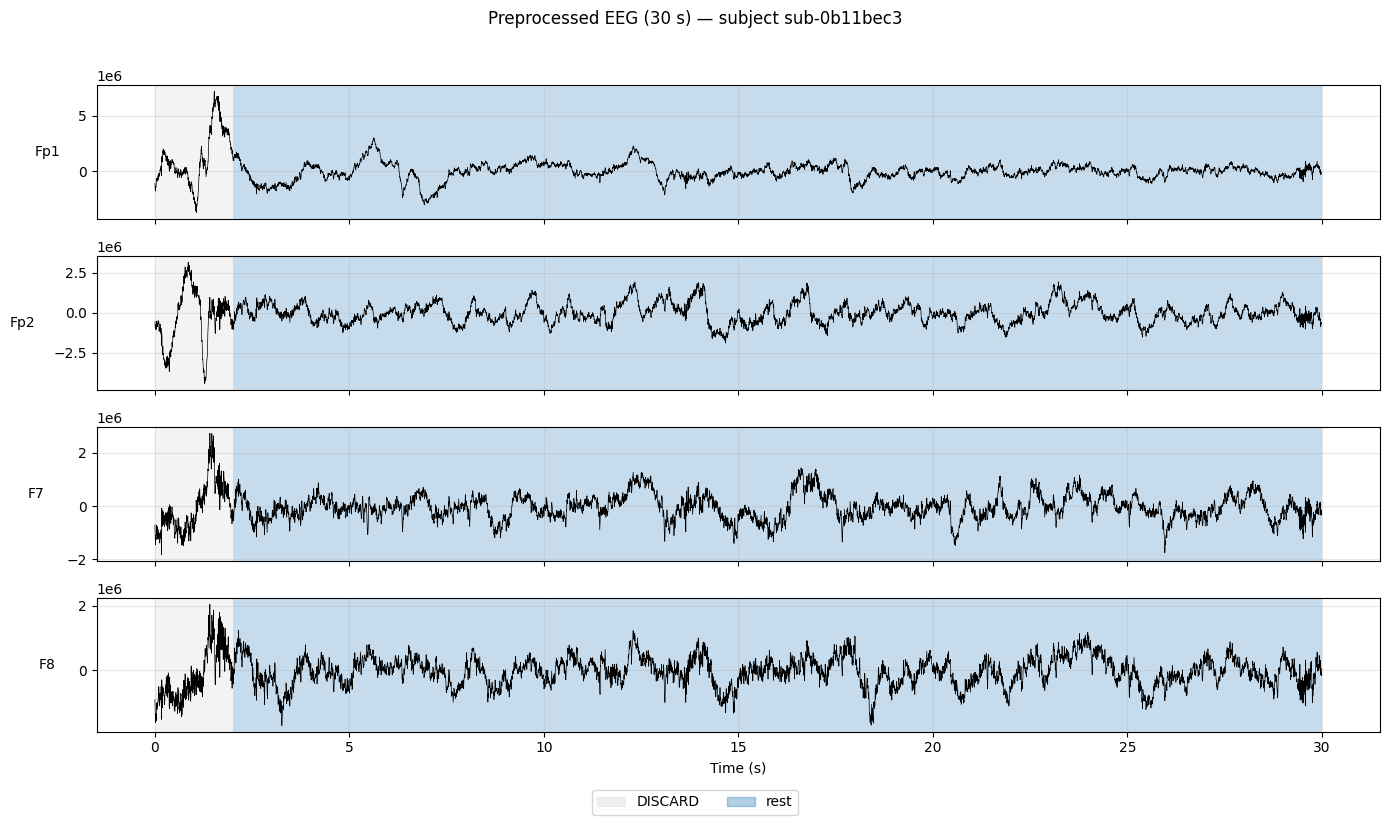

In [11]:
# ---- 4. Representative plot: 30 s of one subject's preprocessed signal,
#         with coloured background bands per region label.
demo_path = sorted(CONFIG["DATA_DIR"].glob("*.xdf"))[0]
demo_eeg, demo_ts, demo_fs_meta, demo_mk = load_xdf_file(demo_path)
demo_raw = preprocess_raw(demo_eeg, demo_ts, demo_fs_meta, CONFIG["CH_NAMES"], demo_mk)
demo_labels = build_label_timeline(demo_mk, demo_eeg.shape[1], demo_ts, CONFIG)

WINDOW_S = 30.0
sfreq = demo_raw.info["sfreq"]

# Anchor the 30-second slice so it contains a real artifact region for illustration.
non_discard = np.where(demo_labels != "DISCARD")[0]
start_sample = max(0, non_discard[0] - int(2 * sfreq)) if len(non_discard) else 0
n_show = int(WINDOW_S * sfreq)
end_sample = min(start_sample + n_show, demo_raw.n_times)

data = demo_raw.get_data(start=start_sample, stop=end_sample)
times = np.arange(end_sample - start_sample) / sfreq
labels_slice = demo_labels[start_sample:end_sample]

# Colour map: one colour per fine label, grey for DISCARD.
unique_lbls = list(np.unique(labels_slice))
cmap = plt.get_cmap("tab10")
colour_map: dict[str, object] = {}
colour_idx = 0
for lbl in unique_lbls:
    if lbl == "DISCARD":
        colour_map[lbl] = "lightgrey"
    else:
        colour_map[lbl] = cmap(colour_idx % 10)
        colour_idx += 1

# Contiguous label runs → one axvspan per run.
run_starts = np.concatenate(([0],
                             np.where(labels_slice[1:] != labels_slice[:-1])[0] + 1))
run_ends   = np.concatenate((run_starts[1:], [len(labels_slice)]))

fig, axes = plt.subplots(CONFIG["N_ACTIVE_CHANNELS"], 1,
                         figsize=(14, 8), sharex=True)
for ax_idx, ax in enumerate(axes):
    ax.plot(times, data[ax_idx] * 1e6, color="black", lw=0.5)
    for rs, re in zip(run_starts, run_ends):
        ax.axvspan(times[rs], times[min(re, len(times) - 1)],
                   color=colour_map[labels_slice[rs]], alpha=0.25, linewidth=0)
    ax.set_ylabel(CONFIG["ACTIVE_CH_NAMES"][ax_idx], rotation=0, labelpad=22,
                  va="center")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle(
    f"Preprocessed EEG (30 s) — subject {_subject_id_from_path(demo_path)}",
    y=0.995,
)

legend_handles = [mpatches.Patch(color=col, alpha=0.35, label=lbl)
                  for lbl, col in colour_map.items()]
fig.legend(handles=legend_handles, loc="lower center",
           ncol=min(len(colour_map), 6), bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=(0, 0.02, 1, 0.98))
plt.show()

In [12]:
# ---- 5. Final summary: every output file with its size on disk ----
def _human_size(n_bytes: int) -> str:
    """Format a byte count as a short human-readable string."""
    size = float(n_bytes)
    for unit in ("B", "KB", "MB", "GB"):
        if size < 1024.0:
            return f"{size:7.2f} {unit}"
        size /= 1024.0
    return f"{size:7.2f} TB"


print("=" * 62)
print("Preprocessing pipeline complete.")
print("=" * 62)
print(f"Output directory : {CONFIG['OUTPUT_DIR'].resolve()}")
print()
for path in (features_path, windows_raw_path, summary_path):
    if path.exists():
        print(f"  ✓ {path.name:<22s} {_human_size(path.stat().st_size)}")
    else:
        print(f"  ✗ {path.name:<22s} MISSING")
print()
print(f"Total windows kept   : {len(y_fine)}")
print(f"Feature matrix shape : {X.shape}")
print(f"Raw windows shape    : {windows_raw.shape}")

Preprocessing pipeline complete.
Output directory : C:\Users\Mirko\Downloads\AY_2526_project_group_03\notebooks\processed_xdf

  ✓ features.pkl             28.31 MB
  ✓ windows_raw.pkl         174.27 MB
  ✓ window_summary.csv      440.10 KB

Total windows kept   : 11418
Feature matrix shape : (11418, 324)
Raw windows shape    : (11418, 4, 500)
